# Cost training and Calibration

We train one XGBoost regressor per LLM using TF–IDF prompt features and prompt length to predict response cost.
Each training cost is divided by that LLM’s mean training cost; predictions are converted back to dollars by flooring normalized predictions at 0.000001 and multiplying by the saved training mean.
We save the trained regressors and normalization values, then assess prediction errors and expected-cost reliability on the separate calibration partition.

## Load the data

In [1]:
from pathlib import Path

PROJECT_DIR = None

for folder in [Path.cwd()] + list(Path.cwd().parents):
    if (folder / "1_data_preparation").is_dir():
        PROJECT_DIR = folder
        break

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Run this notebook from inside the project."
    )

DATA_DIR = (
    PROJECT_DIR
    / "1_data_preparation/data/processed/char_tfidf_50k"
)

import numpy as np
import pandas as pd

train_costs = pd.read_pickle(
    DATA_DIR / "train_costs.pkl"
).astype(float)

assert np.isfinite(train_costs.to_numpy()).all()
assert train_costs.ge(0).all().all()

print("Shape:", train_costs.shape)
display(train_costs.head())

Shape: (21900, 11)


,WizardLM/WizardLM-13B-V1.2,claude-instant-v1,claude-v1,claude-v2,gpt-3.5-turbo-1106,gpt-4-1106-preview,meta/code-llama-instruct-34b-chat,meta/llama-2-70b-chat,mistralai/mistral-7b-chat,mistralai/mixtral-8x7b-chat,zero-one-ai/Yi-34B-Chat
0,0.000103,0.000099,0.004904,0.006488,0.000527,0.00973,0.000236,0.000266,0.000062,0.000166,0.000250
3,0.000104,0.000093,0.003088,0.004960,0.000243,0.00908,0.000315,0.000287,0.000045,0.000117,0.000318
4,0.000112,0.000090,0.002272,0.004912,0.000227,0.01322,0.000190,0.000254,0.000039,0.000097,0.000210
5,0.000076,0.000134,0.005640,0.005976,0.000196,0.00837,0.000150,0.000247,0.000022,0.000248,0.000210
6,0.000049,0.000090,0.002600,0.002336,0.000303,0.01069,0.000294,0.000271,0.000035,0.000099,0.000258


### Scaling the cost

In [2]:
DISPLAY_COST_SCALE = 1000
NORMALIZED_PREDICTION_FLOOR = 1e-6

cost_training_means = train_costs.mean(axis=0)

assert np.isfinite(cost_training_means.to_numpy()).all()
assert cost_training_means.gt(0).all()

train_cost_targets = train_costs.div(
    cost_training_means,
    axis="columns",
)

np.testing.assert_allclose(
    train_cost_targets.mean().to_numpy(),
    1.0,
)

cost_summary = train_cost_targets.describe(
    percentiles=[0.50, 0.90, 0.99]
).T

display(
    cost_summary[
        ["mean", "50%", "90%", "99%", "max"]
    ].round(4)
)

,mean,50%,90%,99%,max
WizardLM/WizardLM-13B-V1.2,1.0,0.7617,2.1658,2.9151,6.3449
claude-instant-v1,1.0,0.6449,2.5108,3.5296,8.1808
claude-v1,1.0,0.7053,2.3061,3.3398,10.2880
claude-v2,1.0,0.6379,2.5021,3.5069,8.0814
gpt-3.5-turbo-1106,1.0,0.7696,2.1360,3.1608,8.0500
gpt-4-1106-preview,1.0,0.5821,2.6257,4.1144,15.3813
meta/code-llama-instruct-34b-chat,1.0,0.8124,1.9498,2.7036,6.1788
meta/llama-2-70b-chat,1.0,0.8401,1.9336,2.6315,14.4065
mistralai/mistral-7b-chat,1.0,0.8018,1.9760,2.7340,18.1305
mistralai/mixtral-8x7b-chat,1.0,0.8341,1.9848,2.6851,12.3013


In [3]:
MODEL_NAME = "gpt-4-1106-preview"

display(pd.DataFrame({
    "original_dollars": train_costs[MODEL_NAME].head(10),
    "scaled_target": train_cost_targets[MODEL_NAME].head(10),
}))

,original_dollars,scaled_target
0,0.00973,2.950130
3,0.00908,2.753051
4,0.01322,4.008296
5,0.00837,2.537779
6,0.01069,3.241202
7,0.00607,1.840420
8,0.00838,2.540811
13,0.02058,6.239844
14,0.00725,2.198196
17,0.00905,2.743955


## Training cost

In [4]:
#Load the model
import sys
import importlib

module_dir = str(PROJECT_DIR / "2b_cost_training_calibration")

if module_dir not in sys.path:
    sys.path.insert(0, module_dir)

import cost_model_xgb as cost_module

importlib.invalidate_caches()
importlib.reload(cost_module)

train_cost_model = cost_module.train_cost_model

print("Training function loaded:", callable(train_cost_model))

Training function loaded: True


In [5]:
# Load training data set
from scipy.sparse import load_npz

X_train = load_npz(DATA_DIR / "X_train.npz")

train_questions = pd.read_pickle(
    DATA_DIR / "train_questions.pkl"
)

assert train_questions.index.equals(train_cost_targets.index)
assert X_train.shape[0] == len(train_cost_targets)

print("Feature matrix:", X_train.shape)

Feature matrix: (21900, 50001)


In [6]:
# Cost Training
from time import perf_counter

cost_models = {}
cost_training_times = {}

for model_name in train_cost_targets.columns:
    print(f"Training cost predictor: {model_name}", flush=True)

    y_cost = train_cost_targets[model_name].to_numpy()

    start = perf_counter()

    fitted_model = train_cost_model(
        X_train,
        y_cost,
    )

    elapsed = perf_counter() - start

    cost_models[model_name] = fitted_model
    cost_training_times[model_name] = elapsed

    print(f"Finished in {elapsed:.1f} seconds\n", flush=True)

Training cost predictor: WizardLM/WizardLM-13B-V1.2
Finished in 10.6 seconds

Training cost predictor: claude-instant-v1
Finished in 10.4 seconds

Training cost predictor: claude-v1
Finished in 10.5 seconds

Training cost predictor: claude-v2
Finished in 10.7 seconds

Training cost predictor: gpt-3.5-turbo-1106
Finished in 10.9 seconds

Training cost predictor: gpt-4-1106-preview
Finished in 10.5 seconds

Training cost predictor: meta/code-llama-instruct-34b-chat
Finished in 11.2 seconds

Training cost predictor: meta/llama-2-70b-chat
Finished in 10.9 seconds

Training cost predictor: mistralai/mistral-7b-chat
Finished in 10.0 seconds

Training cost predictor: mistralai/mixtral-8x7b-chat
Finished in 11.6 seconds

Training cost predictor: zero-one-ai/Yi-34B-Chat
Finished in 12.1 seconds



In [7]:
print("Stored cost models:", len(cost_models))

Stored cost models: 11


In [8]:
#Inspect the results

results = []

train_cost_predictions = pd.DataFrame(
    index=train_costs.index
)

assert X_train.shape[0] == len(train_costs)

for model_name, model in cost_models.items():
    observed = (
        train_costs[model_name].to_numpy()
        * DISPLAY_COST_SCALE
    )

    raw_prediction = model.predict(X_train)

    predicted = (
        np.maximum(raw_prediction, NORMALIZED_PREDICTION_FLOOR)
        * cost_training_means[model_name]
        * DISPLAY_COST_SCALE
    )

    assert np.isfinite(predicted).all()

    train_cost_predictions[model_name] = predicted

    baseline_mse = np.mean(
        (observed - observed.mean()) ** 2
    )
    model_mse = np.mean((observed - predicted) ** 2)

    results.append({
        "LLM": model_name,
        "baseline_RMSE": np.sqrt(baseline_mse),
        "model_RMSE": np.sqrt(model_mse),
        "MSE_reduction_pct": (
            100 * (1 - model_mse / baseline_mse)
            if baseline_mse > 0 else np.nan
        ),
        "MAE": np.mean(np.abs(predicted - observed)),
        "mean_error": np.mean(predicted - observed),
        "negative_predictions": int((raw_prediction < 0).sum()),
        "training_seconds": cost_training_times[model_name],
    })

cost_training_diagnostics = pd.DataFrame(
    results
).set_index("LLM")

display(cost_training_diagnostics.round(4))

,baseline_RMSE,model_RMSE,MSE_reduction_pct,MAE,mean_error,negative_predictions,training_seconds
LLM,,,,,,,
WizardLM/WizardLM-13B-V1.2,0.0534,0.0140,93.1466,0.0071,-0.0000,0,10.6047
claude-instant-v1,0.2104,0.0608,91.6629,0.0288,-0.0001,0,10.4151
claude-v1,1.8051,0.5391,91.0808,0.2543,-0.0008,0,10.5137
claude-v2,2.2002,0.5575,93.5794,0.2721,-0.0000,0,10.7409
gpt-3.5-turbo-1106,0.1812,0.0555,90.6284,0.0281,-0.0000,0,10.8526
gpt-4-1106-preview,3.4422,1.1564,88.7128,0.5225,-0.0006,0,10.5356
meta/code-llama-instruct-34b-chat,0.1114,0.0299,92.7842,0.0158,-0.0000,0,11.2060
meta/llama-2-70b-chat,0.1331,0.0361,92.6494,0.0181,-0.0001,0,10.8967
mistralai/mistral-7b-chat,0.0376,0.0196,72.8520,0.0060,-0.0000,0,10.0157


## Save training

In [9]:
import json
import shutil
import xgboost

COST_MODEL_DIR = PROJECT_DIR / "artifacts" / "cost_xgb"
COST_MODEL_DIR.mkdir(parents=True, exist_ok=True)

assert set(cost_models) == set(train_cost_targets.columns)

model_files = {}

for i, (model_name, model) in enumerate(cost_models.items()):

    # Same compatibility workaround as for score models,
    # but these models are regressors.
    if not hasattr(model, "_estimator_type"):
        model._estimator_type = "regressor"

    filename = f"cost_{i:02d}.ubj"
    model.save_model(COST_MODEL_DIR / filename)

    model_files[model_name] = filename

cost_metadata = {
    "model_files": model_files,
    "target_transform": "divide_by_training_mean",
    "training_mean_costs": cost_training_means.to_dict(),
    "normalized_prediction_floor": NORMALIZED_PREDICTION_FLOOR,
    "n_features": X_train.shape[1],
    "xgboost_version": xgboost.__version__,
    "calibrated": False,
}

with (COST_MODEL_DIR / "metadata.json").open("w") as file:
    json.dump(cost_metadata, file, indent=2)

shutil.copy2(
    DATA_DIR / "preprocessing.joblib",
    COST_MODEL_DIR / "preprocessing.joblib",
)

print("Saved cost predictors:", len(model_files))

Saved cost predictors: 11


In [10]:
# Verify saving
from xgboost import XGBRegressor

with (COST_MODEL_DIR / "metadata.json").open() as file:
    saved_cost_metadata = json.load(file)

loaded_cost_models = {}

for model_name, filename in saved_cost_metadata["model_files"].items():
    model = XGBRegressor(n_jobs=4)

    if not hasattr(model, "_estimator_type"):
        model._estimator_type = "regressor"

    model.load_model(COST_MODEL_DIR / filename)
    loaded_cost_models[model_name] = model

    np.testing.assert_allclose(
        cost_models[model_name].predict(X_train[:5]),
        model.predict(X_train[:5]),
        rtol=1e-6,
        atol=1e-7,
    )

print("All reloaded cost predictions match.")

All reloaded cost predictions match.


## Calibration diagnostics

In [11]:
from scipy.sparse import load_npz

X_calibration = load_npz(DATA_DIR / "X_calibration.npz")

calibration_costs = pd.read_pickle(
    DATA_DIR / "calibration_costs.pkl"
).astype(float)

calibration_questions = pd.read_pickle(
    DATA_DIR / "calibration_questions.pkl"
)

assert calibration_questions.index.equals(calibration_costs.index)
assert X_calibration.shape[0] == len(calibration_costs)
assert X_calibration.shape[1] == saved_cost_metadata["n_features"]
assert set(loaded_cost_models) == set(calibration_costs.columns)

# Use the scaling factor saved with the models.
saved_cost_means = pd.Series(
    saved_cost_metadata["training_mean_costs"]
)

saved_prediction_floor = saved_cost_metadata[
    "normalized_prediction_floor"
]

calibration_cost_targets = (
    calibration_costs * DISPLAY_COST_SCALE
)

print("Calibration features:", X_calibration.shape)

Calibration features: (3648, 50001)


In [12]:
results = []

calibration_cost_predictions = pd.DataFrame(
    index=calibration_cost_targets.index
)

for model_name in calibration_cost_targets.columns:
    model = loaded_cost_models[model_name]

    observed = calibration_cost_targets[model_name].to_numpy()
    raw_prediction = model.predict(X_calibration)

    predicted = (
        np.maximum(raw_prediction, saved_prediction_floor)
        * saved_cost_means[model_name]
        * DISPLAY_COST_SCALE
    )

    assert np.isfinite(predicted).all()

    calibration_cost_predictions[model_name] = predicted

    training_mean = (
        saved_cost_means[model_name] * DISPLAY_COST_SCALE
    )

    baseline_mse = np.mean((observed - training_mean) ** 2)
    model_mse = np.mean((observed - predicted) ** 2)

    results.append({
        "LLM": model_name,
        "training_RMSE": cost_training_diagnostics.loc[
            model_name, "model_RMSE"
        ],
        "calibration_RMSE": np.sqrt(model_mse),
        "baseline_RMSE": np.sqrt(baseline_mse),
        "MSE_reduction_pct": (
            100 * (1 - model_mse / baseline_mse)
            if baseline_mse > 0 else np.nan
        ),
        "MAE": np.mean(np.abs(predicted - observed)),
        "mean_error": np.mean(predicted - observed),
        "negative_predictions": int((raw_prediction < 0).sum()),
    })

cost_calibration_diagnostics = pd.DataFrame(
    results
).set_index("LLM")

display(cost_calibration_diagnostics.round(4))

,training_RMSE,calibration_RMSE,baseline_RMSE,MSE_reduction_pct,MAE,mean_error,negative_predictions
LLM,,,,,,,
WizardLM/WizardLM-13B-V1.2,0.0140,0.0154,0.0535,91.7426,0.0074,-0.0002,0
claude-instant-v1,0.0608,0.0701,0.2106,88.9289,0.0306,-0.0001,0
claude-v1,0.5391,0.6884,1.8592,86.2924,0.2763,-0.0273,0
claude-v2,0.5575,0.6488,2.2102,91.3833,0.2943,-0.0102,0
gpt-3.5-turbo-1106,0.0555,0.1162,0.2108,69.6482,0.0314,-0.0029,0
gpt-4-1106-preview,1.1564,1.4539,3.4797,82.5423,0.5595,-0.0025,0
meta/code-llama-instruct-34b-chat,0.0299,0.0335,0.1119,91.0145,0.0161,-0.0001,0
meta/llama-2-70b-chat,0.0361,0.0383,0.1313,91.4868,0.0191,0.0002,0
mistralai/mistral-7b-chat,0.0196,0.0232,0.0366,59.8174,0.0065,0.0000,0


In [13]:
# Inspect GPT-3.5’s largest errors.
MODEL_NAME = "gpt-3.5-turbo-1106"

error_details = calibration_questions[
    ["sample_id", "eval_name"]
].copy()

error_details["observed_cost"] = (
    calibration_cost_targets[MODEL_NAME]
)

error_details["predicted_cost"] = (
    calibration_cost_predictions[MODEL_NAME]
)

error_details["absolute_error"] = (
    error_details["predicted_cost"]
    - error_details["observed_cost"]
).abs()

display(
    error_details.nlargest(10, "absolute_error").round(4)
)

,sample_id,eval_name,observed_cost,predicted_cost,absolute_error
5496,grade-school-math.dev.3086,grade-school-math,6.443,0.5614,5.8816
35193,mtbench.dev.15,mtbench,1.374,0.3247,1.0493
35207,mtbench.dev.28,mtbench,1.207,0.3920,0.8150
35184,mtbench-reference.dev.8,mtbench-reference,1.325,0.6800,0.6450
35190,mtbench.dev.12,mtbench,0.976,0.4152,0.5608
22437,mmlu-college-medicine.val.66,mmlu-college-medicine,1.007,0.4818,0.5252
2162,chinese-remainder-theorem.dev.11,chinese-remainder-theorem,1.034,0.5373,0.4967
22467,mmlu-college-medicine.val.93,mmlu-college-medicine,0.991,0.5119,0.4791
4870,grade-school-math.dev.2520,grade-school-math,1.106,0.6606,0.4454
5050,grade-school-math.dev.2684,grade-school-math,0.973,0.5383,0.4347


In [14]:
# Measure how much the largest error contributes to total squared error.
squared_errors = error_details["absolute_error"] ** 2

largest_error_id = squared_errors.idxmax()

share = (
    squared_errors.loc[largest_error_id]
    / squared_errors.sum()
)

# Sensitivity check only; keep the observation in official metrics.
remaining_errors = squared_errors.drop(index=largest_error_id)

print(
    "Largest observation's share of squared error:",
    f"{100 * share:.1f}%",
)

print(
    "RMSE on all calibration prompts:",
    f"{np.sqrt(squared_errors.mean()):.4f}",
)

print(
    "RMSE excluding that one observation, for diagnosis only:",
    f"{np.sqrt(remaining_errors.mean()):.4f}",
)

Largest observation's share of squared error: 70.3%
RMSE on all calibration prompts: 0.1162
RMSE excluding that one observation, for diagnosis only: 0.0633


In [15]:
cost_bin_tables = {}

for model_name in calibration_cost_targets.columns:
    details = pd.DataFrame({
        "predicted": calibration_cost_predictions[model_name],
        "observed": calibration_cost_targets[model_name],
    })

    details["bin"] = pd.qcut(
        details["predicted"],
        q=10,
        duplicates="drop",
    )

    table = (
        details.groupby("bin", observed=True)
        .agg(
            count=("observed", "size"),
            prediction_min=("predicted", "min"),
            prediction_max=("predicted", "max"),
            mean_prediction=("predicted", "mean"),
            mean_observed=("observed", "mean"),
        )
    )

    table["gap"] = (
        table["mean_prediction"] - table["mean_observed"]
    )

    cost_bin_tables[model_name] = table

display(cost_bin_tables["gpt-3.5-turbo-1106"].round(4))

,count,prediction_min,prediction_max,mean_prediction,mean_observed,gap
bin,,,,,,
"(0.0683, 0.0841]",365,0.0693,0.0839,0.0770,0.0666,0.0103
"(0.0841, 0.0957]",365,0.0841,0.0957,0.0900,0.0871,0.0029
"(0.0957, 0.111]",365,0.0957,0.1109,0.1025,0.1013,0.0012
"(0.111, 0.129]",364,0.1109,0.1294,0.1200,0.1205,-0.0005
"(0.129, 0.206]",365,0.1295,0.2055,0.1502,0.1478,0.0024
"(0.206, 0.255]",365,0.2059,0.2545,0.2353,0.2361,-0.0008
"(0.255, 0.284]",364,0.2547,0.2837,0.2691,0.2699,-0.0008
"(0.284, 0.43]",365,0.2841,0.4296,0.3365,0.3402,-0.0038
"(0.43, 0.521]",365,0.4296,0.5215,0.4819,0.4795,0.0024


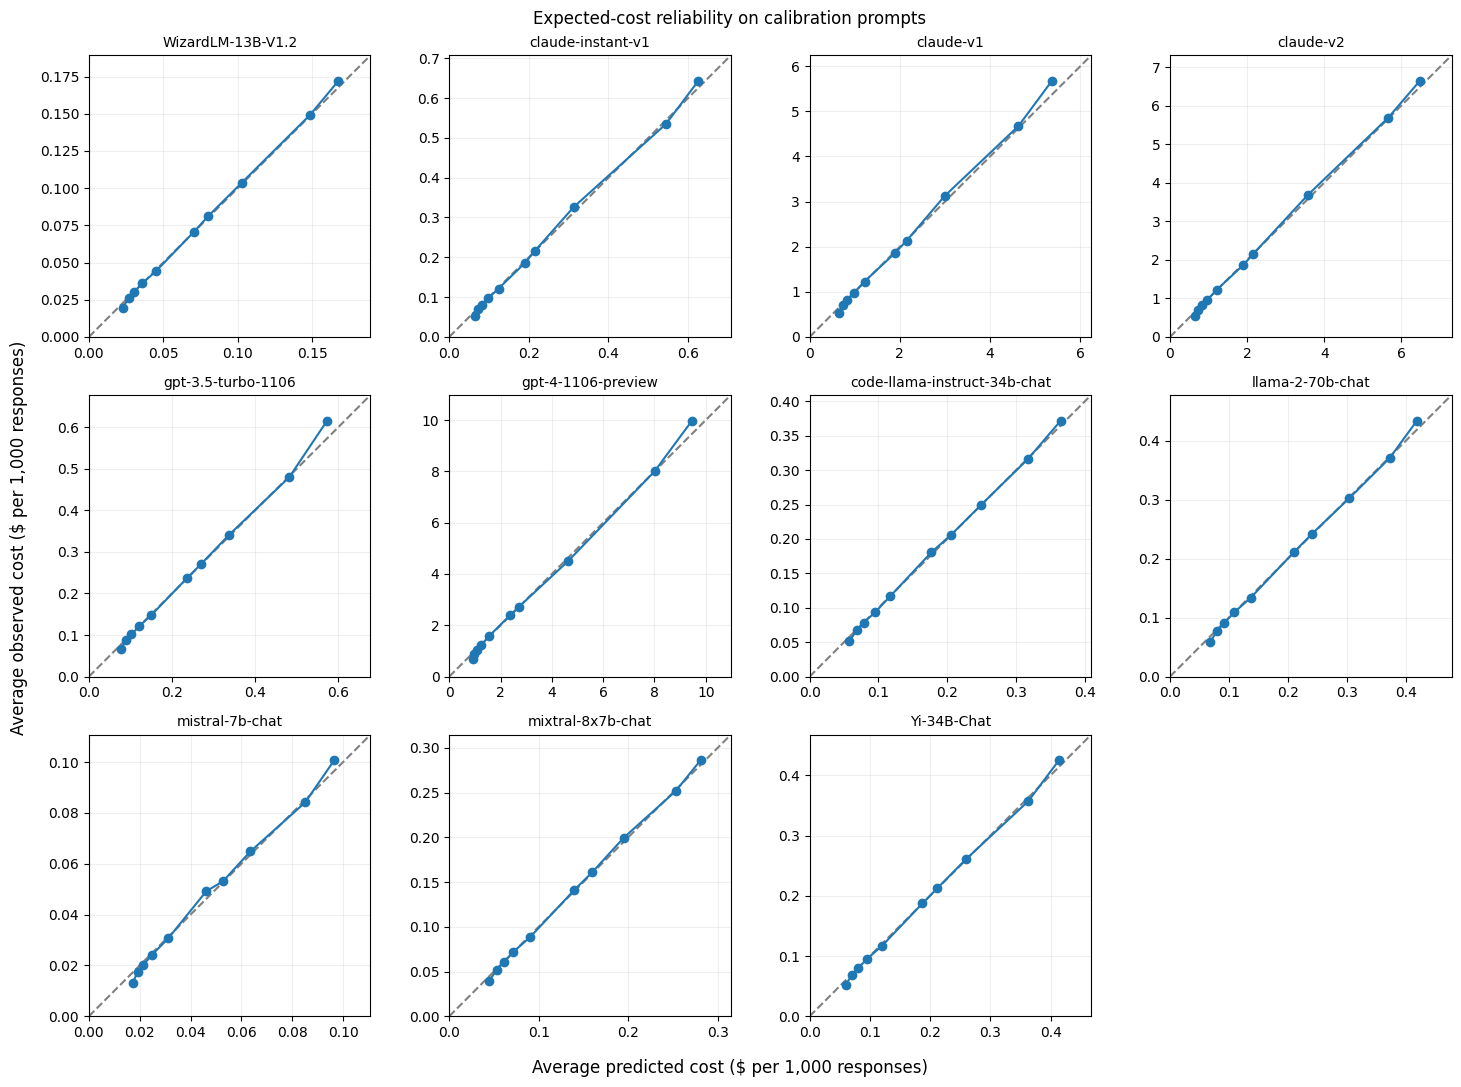

In [16]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 4, figsize=(15, 11))
axes = axes.ravel()

for ax, (model_name, table) in zip(axes, cost_bin_tables.items()):
    upper = max(
        table["mean_prediction"].max(),
        table["mean_observed"].max(),
    ) * 1.1

    ax.plot([0, upper], [0, upper], "--", color="gray")

    ax.plot(
        table["mean_prediction"],
        table["mean_observed"],
        "o-",
    )

    ax.set_title(model_name.split("/")[-1], fontsize=10)
    ax.set_xlim(0, upper)
    ax.set_ylim(0, upper)
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)

for ax in axes[len(cost_bin_tables):]:
    ax.set_visible(False)

fig.supxlabel("Average predicted cost ($ per 1,000 responses)")
fig.supylabel("Average observed cost ($ per 1,000 responses)")
fig.suptitle("Expected-cost reliability on calibration prompts")

plt.tight_layout()
plt.show()

Plots don't show consistent distortion that obviously calls for calibration.